# Contributions

- Dmytro Petrenko: XX%
- Oleh Serdiukov: XX%

# 1.1 Exploratory Data Analysis

## A — Data Structure and Relationships

We inspect the original files, their columns and device relationships.
The prediction target is Failure in readings.csv.

In [89]:
from pathlib import Path
import pandas as pd
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt

DATA = Path("../data")
if not DATA.is_dir():
    DATA = Path("data")

if not DATA.is_dir():
    raise FileNotFoundError("The data folder was not found.")

file_settings = {
    "readings": "\t",
    "units": ",",
    "gateways": ";",
}

tables = {
    name: pd.read_csv(DATA / f"{name}.csv", sep=separator)
    for name, separator in file_settings.items()
}

readings = tables["readings"]
units = tables["units"]
gateways = tables["gateways"]

#file-level structure
inventory = pd.DataFrame([
    {
        "file": f"{name}.csv",
        "separator": repr(file_settings[name]),
        "size_bytes": (DATA / f"{name}.csv").stat().st_size,
        "rows": len(df),
        "columns": df.shape[1],
        "extra_exact_duplicates": df.duplicated().sum(),
    }
    for name, df in tables.items()
])

display(inventory)

#сolumn-level structure and example records
for name, df in tables.items():
    print(f"\n{name}.csv")

    display(pd.DataFrame({
        "data_type": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "unique_non_missing": df.nunique(),
    }))

    display(df.head(3))

,file,separator,size_bytes,rows,columns,extra_exact_duplicates
0,readings.csv,'\t',1214607,13288,11,196
1,units.csv,"','",150618,2000,9,0
2,gateways.csv,';',1525320,16000,10,0



readings.csv


,data_type,missing_count,unique_non_missing
unitId,str,0,2117
ts_cycle,str,0,4270
motorCurrent,float64,0,12933
filterDp,float64,539,12537
temperatureOil,float64,0,13023
pressure_reservoir,float64,0,12693
vibrationRms,float64,522,12398
flowmeter,float64,0,13001
tempBearing,float64,0,13050
discharge_dewpoint,float64,0,13027


,unitId,ts_cycle,motorCurrent,filterDp,temperatureOil,pressure_reservoir,vibrationRms,flowmeter,tempBearing,discharge_dewpoint,Failure
0,U00596,2023/04/15,4.76770,28.08519,47.03756,8.71892,3.54971,31.62776,66.80334,1.83965,0
1,U00540,04 Mar 2023,2.43105,37.32422,66.59793,9.18652,3.10090,26.41965,67.47312,6.77918,0
2,U00927,29 Dec 2023,4.86624,21.25867,69.81401,8.43531,2.96697,30.50532,76.92666,6.36091,0



units.csv


,data_type,missing_count,unique_non_missing
commission_year,int64,0,13
unitId,int64,0,2000
codeLine,str,0,6
owner_operator,str,0,40
id_depot,int64,0,120
serviceHours,float64,100,1866
serialNumber,str,0,2000
class_duty,str,0,20
installRegion,str,0,59


,commission_year,unitId,codeLine,owner_operator,id_depot,serviceHours,serialNumber,class_duty,installRegion
0,2017,1,L4,Williams-Nicholson,34,25682.3,HS-6251-99692,normal,Serpa
1,2023,2,L6,"Fields, Castillo and Gibson",10,5238.9,XA-1366-57511,1,Wernigerode
2,2020,3,L6,Holzapfel,109,16148.7,DU-5060-76112,heavy,Vila Nova de Foz Côa



gateways.csv


,data_type,missing_count,unique_non_missing
Vendor,str,0,40
version_firmware,str,0,3
id_depot,int64,0,120
Lat,float64,0,15595
id_gateway,str,0,16000
dbm_signal,float64,0,596
lon,float64,0,15587
seenLast,str,0,1600
unitId,float64,14000,2000
Ipv4,str,0,16000


,Vendor,version_firmware,id_depot,Lat,id_gateway,dbm_signal,lon,seenLast,unitId,Ipv4
0,Seip Pölitz GbR,v3.4.1,26,39.84446,GW-00000,-58.2,-7.62327,30 Jan 2025,284.0,170.246.170.115
1,Rocha,v3.4.1,58,40.72888,GW-00001,-61.6,-8.70905,2024/10/31,1690.0,187.22.49.52
2,Seip Pölitz GbR,v1.2.5,100,41.08714,GW-00002,-72.2,-7.63215,"08/10/2024, 00:00:00",112.0,111.32.81.45


### Record Structure

- readings.csv: each row contains a device identifier, a timestamp,
  eight sensor measurements and the Failure label.
- units.csv: each row describes a device and its operational metadata.
- gateways.csv: each row describes a gateway, including network details,
  location and a possible device link.

In [90]:
#сreate temporary keys only for relationship analysis
reading_ids = readings["unitId"].astype("string").str.strip()

assert reading_ids.str.fullmatch(r"U[0-9]+", na=False).all(), (
    "Unexpected identifier format in readings."
)

reading_keys = pd.to_numeric(
    reading_ids.str[1:], errors="raise"
).astype("Int64")

unit_keys = units["unitId"].astype("Int64")
gateway_keys = gateways["unitId"].astype("Int64")
linked_gateway_keys = gateway_keys.dropna()

relationship_summary = pd.Series({
    "unique_reading_devices": reading_keys.nunique(),
    "unique_unit_devices": unit_keys.nunique(),
    "missing_unit_keys": unit_keys.isna().sum(),
    "extra_duplicate_unit_keys": unit_keys.duplicated().sum(),
    "readings_without_matching_unit": (
        ~reading_keys.isin(unit_keys)
    ).sum(),
    "gateways_without_device_key": gateway_keys.isna().sum(),
    "extra_duplicate_linked_gateway_keys": (
        linked_gateway_keys.duplicated().sum()
    ),
    "linked_gateways_without_matching_unit": (
        ~linked_gateway_keys.isin(unit_keys)
    ).sum(),
})

display(relationship_summary.to_frame("count"))

,count
unique_reading_devices,2117
unique_unit_devices,2000
missing_unit_keys,0
extra_duplicate_unit_keys,0
readings_without_matching_unit,133
gateways_without_device_key,14000
extra_duplicate_linked_gateway_keys,0
linked_gateways_without_matching_unit,0


### Findings

Device keys in units are complete and unique, supporting a many-to-one
join from readings.

There are 133 unmatched readings and 14,000 gateways without device keys.
The 2,000 linked gateways have unique device keys matching units.
Readings contains 196 extra exact duplicates.

## B — Attribute Distributions and Statistics

We analyse eight sensors, commission_year and serviceHours.
Sensor statistics use reading records; device statistics use device records.
Observed ranges are reported separately from documented operating limits,
which are not provided.

In [91]:
sensors = [
    "motorCurrent", "filterDp", "temperatureOil",
    "pressure_reservoir", "vibrationRms", "flowmeter",
    "tempBearing", "discharge_dewpoint",
]

attributes = {
    **{column: readings[column] for column in sensors},
    **{column: units[column] for column in ["commission_year", "serviceHours"]},
}

statistics = pd.DataFrame({
    name: series.describe()
    for name, series in attributes.items()
}).T

statistics["missing"] = [
    series.isna().sum() for series in attributes.values()
]
statistics["non_finite"] = [
    (~np.isfinite(series.dropna())).sum()
    for series in attributes.values()
]

display(statistics.round(2))

,count,mean,std,min,25%,50%,75%,max,missing,non_finite
motorCurrent,13288.0,5.25,3.55,0.00,3.68,5.04,6.55,99.00,0,0
filterDp,12749.0,24.17,11.38,6.98,16.33,21.42,28.97,120.00,539,0
temperatureOil,13288.0,51.62,60.36,-999.00,46.63,54.89,63.05,95.00,0,0
pressure_reservoir,13288.0,8.71,0.60,6.50,8.30,8.71,9.12,10.50,0,0
vibrationRms,12766.0,3.06,1.63,0.50,1.93,2.72,3.78,14.00,522,0
flowmeter,13288.0,28.00,4.01,15.00,25.32,28.07,30.65,40.00,0,0
tempBearing,13288.0,65.04,8.04,34.74,59.63,65.07,70.48,96.17,0,0
discharge_dewpoint,13288.0,7.98,3.51,-4.78,5.58,7.97,10.38,21.42,0,0
commission_year,2000.0,2020.52,2.49,2012.00,2019.00,2021.00,2022.00,2024.00,0,0
serviceHours,1900.0,13970.87,8745.33,1465.60,7623.02,11715.30,17632.40,45000.00,100,0


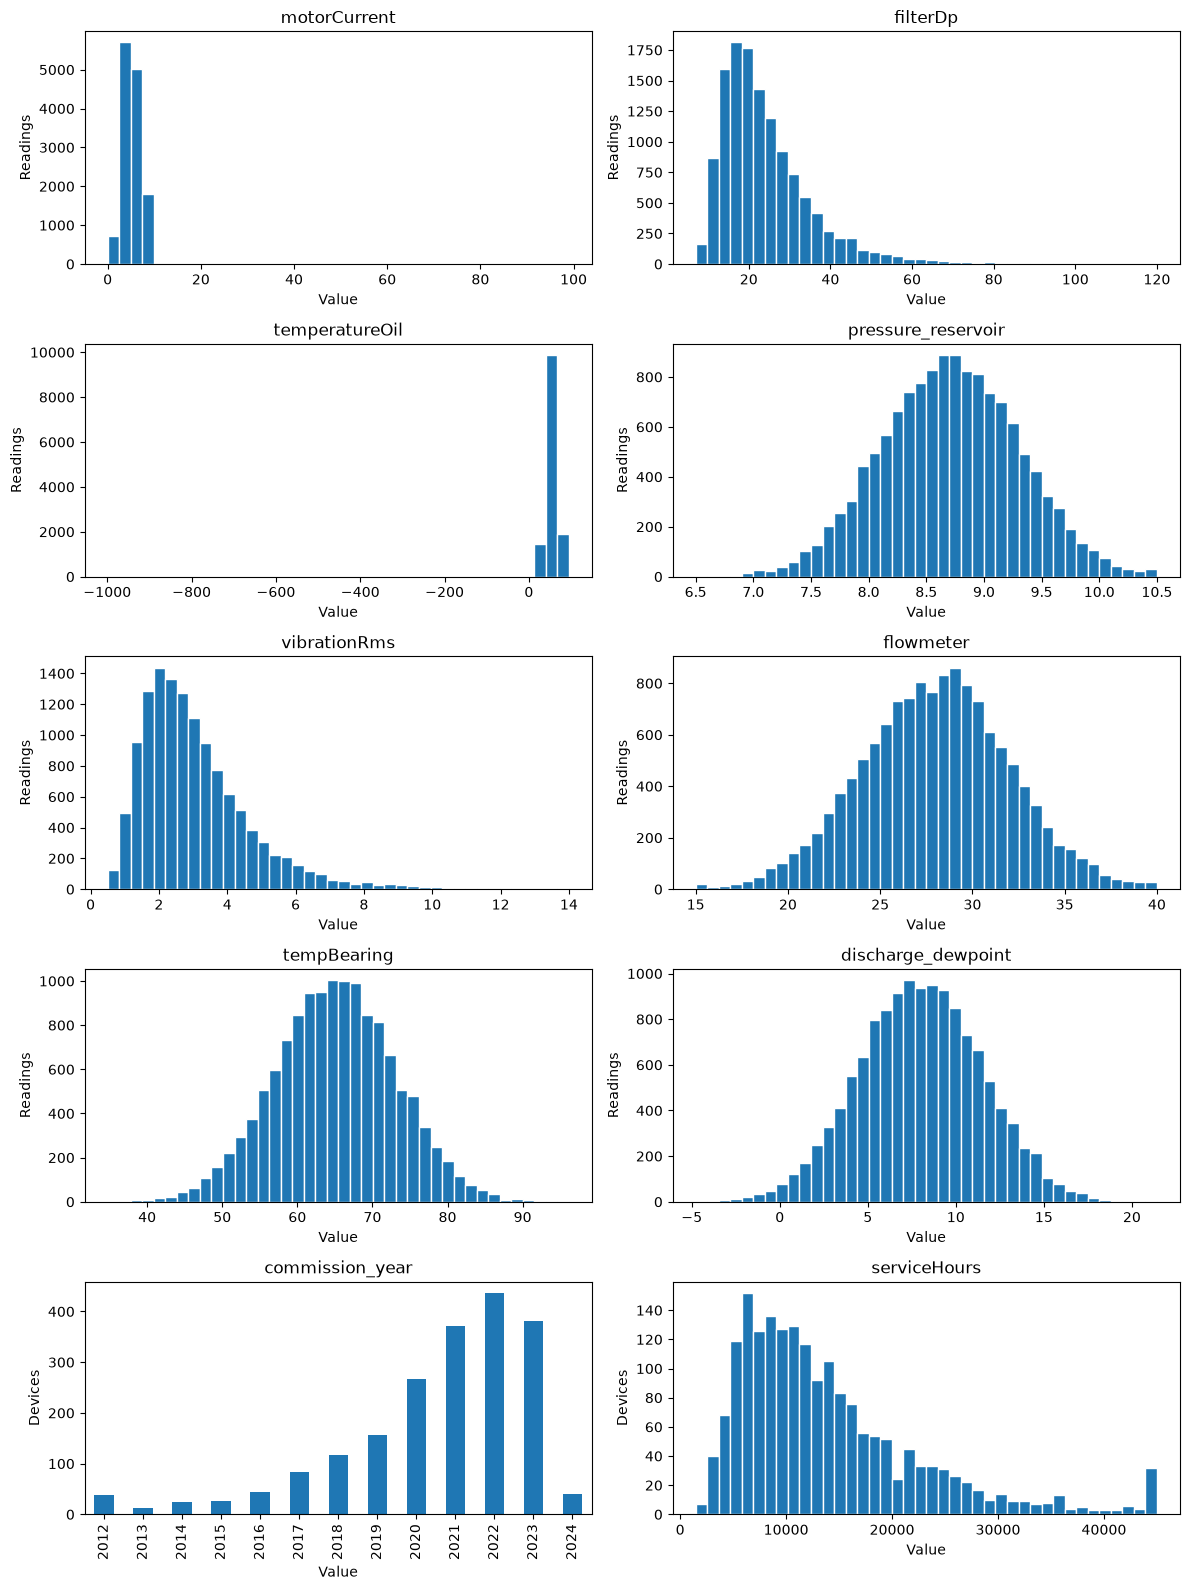

In [92]:
fig, axes = plt.subplots(5, 2, figsize=(12, 16))

for ax, (name, series) in zip(axes.flat, attributes.items()):
    values = series.dropna()
    values = values[np.isfinite(values)]

    if name == "commission_year":
        values.value_counts().sort_index().plot.bar(ax=ax)
        ax.set_ylabel("Devices")
    else:
        ax.hist(values, bins=40, edgecolor="white")
        ax.set_ylabel("Readings" if name in sensors else "Devices")

    ax.set_title(name)
    ax.set_xlabel("Value")

fig.tight_layout()
plt.show()

In [93]:
checks = pd.Series({
    "temperatureOil_equal_to_minus_999": readings["temperatureOil"].eq(-999).sum(),
    "negative_serviceHours": units["serviceHours"].lt(0).sum(),
    "unexpected_Failure_values": (
        readings["Failure"].notna()
        & ~readings["Failure"].isin([0, 1])
    ).sum(),
})

display(checks.to_frame("count"))

,count
temperatureOil_equal_to_minus_999,42
negative_serviceHours,0
unexpected_Failure_values,0


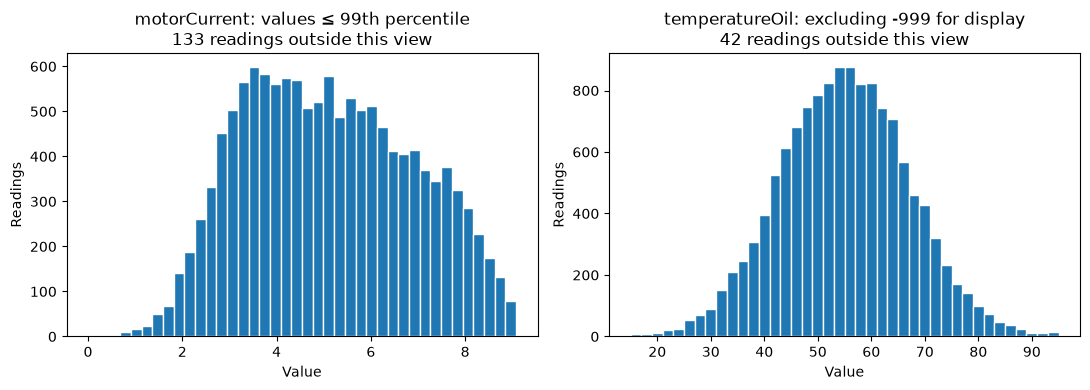

In [94]:
#create two plots for a closer view of the distributions
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

#show motorCurrent up to its 99th percentile
current = readings["motorCurrent"].dropna()
upper = current.quantile(0.99)
central = current[current <= upper]

axes[0].hist(central, bins=40, edgecolor="white")
axes[0].set_title(
    f"motorCurrent: values ≤ 99th percentile\n"
    f"{len(current) - len(central)} readings outside this view"
)

#exclude the suspected invalid temperature code
oil = readings["temperatureOil"].dropna()
visible_oil = oil[oil != -999]

axes[1].hist(visible_oil, bins=40, edgecolor="white")
axes[1].set_title(
    f"temperatureOil: excluding -999 for display\n"
    f"{oil.eq(-999).sum()} readings outside this view"
)

for ax in axes:
    ax.set_xlabel("Value")
    ax.set_ylabel("Readings")

fig.tight_layout()
plt.show()

### Findings

- filterDp, vibrationRms and serviceHours have right-skewed distributions.
- pressure_reservoir, flowmeter, tempBearing and discharge_dewpoint
  appear approximately symmetric; normality has not been tested.
- motorCurrent has a median of 5.04 and a maximum of 99.
- temperatureOil contains 42 values of -999, affecting its mean,
  standard deviation and histogram scale.
- commission_year ranges from 2012 to 2024, with the highest frequency
  in 2022.
- Missing values: filterDp 539, vibrationRms 522, serviceHours 100.
- No infinite values, negative serviceHours or unexpected Failure
  values were found.

Observed ranges do not establish valid operating limits.
Suspicious values require investigation in section 1.2.

## C — Relationships Between Attributes

We examine sensor associations using Spearman correlation.
For this calculation, temperatureOil = -999 is treated as missing.
Each correlation uses rows where both measurements are available.

,motorCurrent,filterDp,temperatureOil,pressure_reservoir,vibrationRms,flowmeter,tempBearing,discharge_dewpoint
motorCurrent,1.00,0.01,0.01,-0.01,-0.01,0.01,-0.01,0.00
filterDp,0.01,1.00,0.01,-0.02,-0.00,-0.01,-0.01,-0.00
temperatureOil,0.01,0.01,1.00,0.01,-0.00,-0.00,0.00,0.01
pressure_reservoir,-0.01,-0.02,0.01,1.00,0.01,-0.00,-0.01,-0.01
vibrationRms,-0.01,-0.00,-0.00,0.01,1.00,-0.01,0.00,-0.00
flowmeter,0.01,-0.01,-0.00,-0.00,-0.01,1.00,-0.01,-0.00
tempBearing,-0.01,-0.01,0.00,-0.01,0.00,-0.01,1.00,0.00
discharge_dewpoint,0.00,-0.00,0.01,-0.01,-0.00,-0.00,0.00,1.00


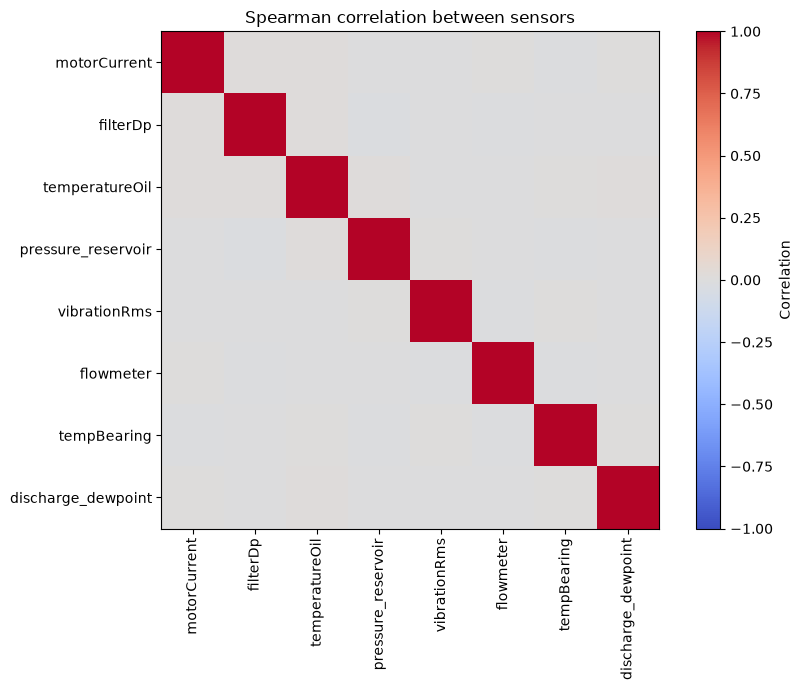

In [95]:
#create an analysis copy of the eight sensor columns
sensor_data = readings[sensors].copy()

#treat -999 as missing for correlation analysis
sensor_data["temperatureOil"] = sensor_data["temperatureOil"].mask(
    sensor_data["temperatureOil"].eq(-999)
)

#calculate rank correlations using available pairs of measurements
correlation = sensor_data.corr(method="spearman")
display(correlation.round(2))

#use a fixed colour scale from -1 to 1
fig, ax = plt.subplots(figsize=(9, 7))
plot = ax.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")

#label sensors and add the colour scale
ax.set_xticks(range(len(sensors)), labels=sensors, rotation=90)
ax.set_yticks(range(len(sensors)), labels=sensors)
ax.set_title("Spearman correlation between sensors")
fig.colorbar(plot, ax=ax, label="Correlation")

#adjust spacing and display the heatmap
fig.tight_layout()
plt.show()

### Pairwise Plots

We compare oil and bearing temperatures, reservoir pressure and flow,
and filter pressure difference and flow.

These pairs are selected for their related measurement roles.
Plots help inspect patterns that Spearman correlation may miss.

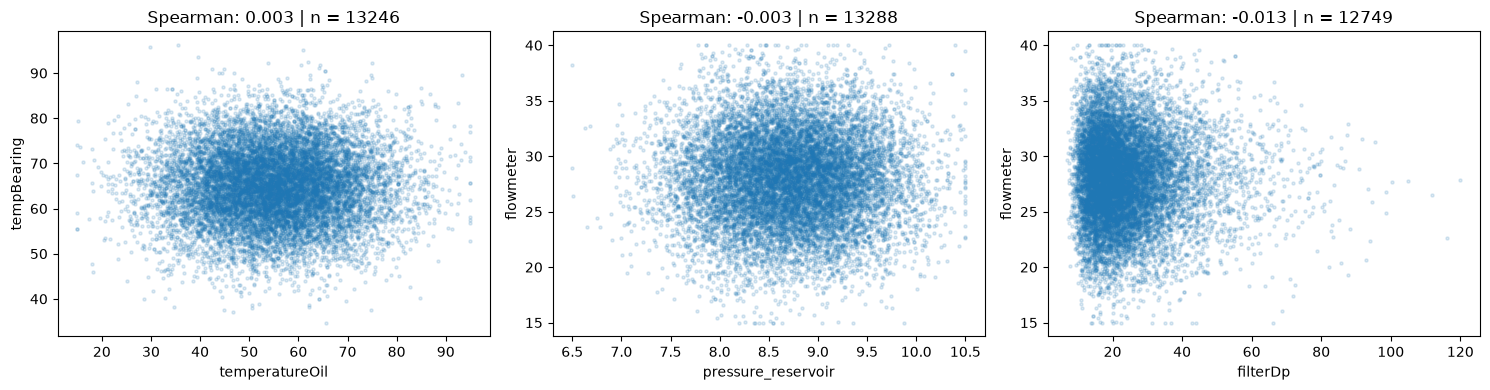

In [96]:
#inspect three sensor pairs for patterns beyond rank correlation
pairs = [
    ("temperatureOil", "tempBearing"),
    ("pressure_reservoir", "flowmeter"),
    ("filterDp", "flowmeter"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (x, y) in zip(axes, pairs):
    #use only rows where both measurements are available
    pair = sensor_data[[x, y]].dropna()

    ax.scatter(pair[x], pair[y], s=5, alpha=0.15)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(
        f"Spearman: {correlation.loc[x, y]:.3f} | n = {len(pair)}"
    )

fig.tight_layout()
plt.show()

### Findings

Pairwise Spearman correlations are close to zero.
No strong monotonic associations were found among the eight sensors.
This does not establish independence or exclude nonlinear relationships.

## D — Relationships with Failure

We compare class frequencies and sensor distributions by Failure.
Oil temperature -999 is excluded using the analysis copy from section C.

In [97]:
#show the class balance
counts = readings["Failure"].value_counts().sort_index()

display(pd.DataFrame({
    "rows": counts,
    "percent": (100 * counts / len(readings)).round(2),
}))

#compare sensor medians and available observations
grouped = sensor_data.groupby(readings["Failure"])

print("Sensor medians:")
display(grouped.median().T.round(2))

print("Available observations:")
display(grouped.count().T)

,rows,percent
Failure,,
0,11663,87.77
1,1625,12.23


Sensor medians:


Failure,0,1
motorCurrent,5.11,4.57
filterDp,21.09,24.48
temperatureOil,54.89,55.39
pressure_reservoir,8.73,8.58
vibrationRms,2.70,2.88
flowmeter,28.11,27.80
tempBearing,64.77,67.32
discharge_dewpoint,7.88,8.67


Available observations:


Failure,0,1
motorCurrent,11663,1625
filterDp,11424,1325
temperatureOil,11629,1617
pressure_reservoir,11663,1625
vibrationRms,11443,1323
flowmeter,11663,1625
tempBearing,11663,1625
discharge_dewpoint,11663,1625


### Sensor Distributions by Failure

Boxplots compare medians and spread between classes.
Outlier markers are hidden; observations are retained.

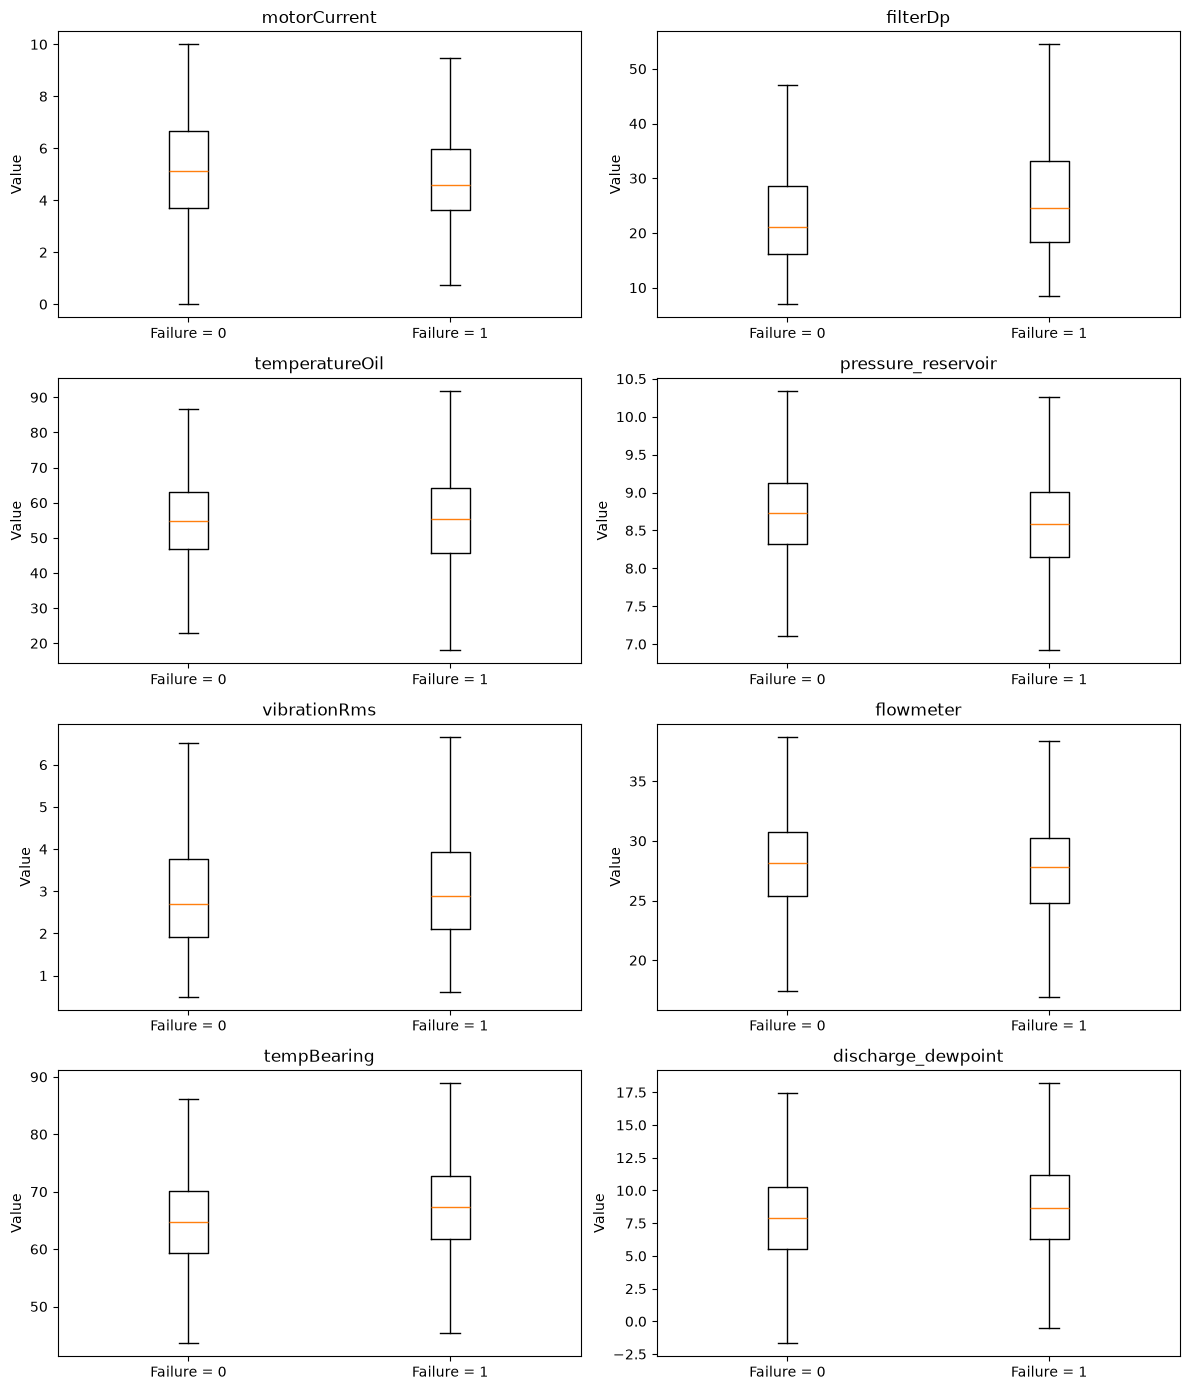

In [98]:
#compare sensor distributions between Failure classes
fig, axes = plt.subplots(4, 2, figsize=(12, 14))

for ax, column in zip(axes.flat, sensors):
    groups = [
        sensor_data.loc[readings["Failure"].eq(label), column].dropna()
        for label in (0, 1)
    ]

    #hide outlier markers for readability
    ax.boxplot(groups, showfliers=False)
    ax.set_xticks([1, 2], labels=["Failure = 0", "Failure = 1"])
    ax.set_title(column)
    ax.set_ylabel("Value")

fig.tight_layout()
plt.show()

In [99]:
# Missing measurement percentages by Failure class
display(
    sensor_data.isna()
    .groupby(readings["Failure"])
    .mean()
    .mul(100)
    .T
    .round(2)
)

Failure,0,1
motorCurrent,0.00,0.00
filterDp,2.05,18.46
temperatureOil,0.29,0.49
pressure_reservoir,0.00,0.00
vibrationRms,1.89,18.58
flowmeter,0.00,0.00
tempBearing,0.00,0.00
discharge_dewpoint,0.00,0.00


### Findings

Failure = 1 accounts for 12.23% of readings.

Compared with Failure = 0, failure-labelled readings have higher medians
for filterDp (24.48 vs 21.09), tempBearing (67.32 vs 64.77) and
discharge_dewpoint (8.67 vs 7.88).
Motor current has a lower median (4.57 vs 5.11).

Missingness also differs: filterDp is missing in 18.46% of failure rows
versus 2.05% of non-failure rows; vibrationRms in 18.58% versus 1.89%.

These are descriptive associations, not evidence of causation or
advance failure prediction.

## E — Initial Project Decisions

- Sensor correlations show no strong monotonic associations.
  Nonlinear relationships remain possible.
- Investigate filterDp, tempBearing, discharge_dewpoint and motorCurrent
  as candidate predictors based on class differences.
- Investigate missingness indicators and whether missing measurements
  occur before or after failure.
- Join readings with units through the normalized device key to examine
  device metadata. Retain and flag unmatched records.
- Check the timing of metadata before using it as a predictor.
- Address duplicates, invalid values and inconsistent formats in 1.2.
- Account for class imbalance and repeated measurements when evaluating
  future models.